# Does NYC Walks pedestrian volume belong in the crash models? (#33)

`preprocessing/pedestrians.py` gives every site the busiest NYC Walks segment within 100 ft. That's MIT City Form Lab's modeled pedestrians in the weekday 8–9 AM, 12:30–1:30 PM and 5–6 PM peak hours for 2018–19 (Sevtsuk et al., *Nature Cities*). Issue #33 keeps the feature only if it does one of two things:

1. **It improves the pooled 2023–25 holdout** (top-k capture, deviance).
2. **It makes comparison sites more like camera sites.** That means camera sites differ in foot traffic in a way the road features don't already capture, so the EB baseline needs it.

Two model specs are tested, each with and without `FEATURE_SETS["pedestrian"]`:
- **Standard:** the midterm KSI risk model (crash history, site, crash types and road features).
- **Road only:** site and road features, with no crash history. This is the shape of the EB baseline, so it is the test that matters most for the camera-effect step.

The outcome is KSI. The injury-crash and pedestrian-injury robustness checks aren't run yet, because `NegativeBinomialModel` doesn't converge on those outcomes with these features (see the PR).

In [1]:
import logging
import sys
import warnings
from pathlib import Path

sys.path.append("..")
warnings.filterwarnings("ignore", category=RuntimeWarning)
logging.getLogger().setLevel(logging.WARNING)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, NullFormatter, PercentFormatter

from data.download import download_nycwalks
from model.count_models import NegativeBinomialModel
from preprocessing.panel import FEATURE_SETS, load_panel
from preprocessing.pedestrians import add_pedestrian_features, load_pedestrian_features
from preprocessing.roadway import add_roadway_features, load_roadway_features_by_year
from validation.validate import poisson_deviance, pooled_holdout, top_k_capture
from viz.style import COMPARISON, FULL_WIDTH, INK_2, MODEL, MUTED, SURFACE, use_style

use_style()
OUT = Path("outputs/pedestrian_exposure")
OUT.mkdir(parents=True, exist_ok=True)
SOURCE = "Source: MIT City Form Lab NYC Walks (2018–19); NYPD Motor Vehicle Collisions; DCP LION."
TOP_K = (100, 1000)
N_BOOT = 500
rng = np.random.default_rng(33)


def source(fig, text=SOURCE):
    """Source line under the lowest drawn element."""
    fig.canvas.draw()
    bottom = fig.get_tightbbox(fig.canvas.get_renderer()).y0 / fig.get_figheight()
    fig.text(0.0, bottom - 0.03, text, fontsize=7.5, color=MUTED, ha="left", va="top")


def save(fig, name):
    fig.savefig(OUT / f"{name}.png")

In [2]:
download_nycwalks()  # no-op once data/nycwalks/ exists
panel, scoring, sites = load_panel()
panel = add_roadway_features(panel, load_roadway_features_by_year(sites))
ped = load_pedestrian_features(sites)
panel = add_pedestrian_features(panel, ped)
print(f"{len(sites):,} sites; {ped['ped_volume'].isna().mean():.1%} have no NYC Walks segment within 100 ft")

165,674 sites; 4.6% have no NYC Walks segment within 100 ft


## 1. Holdout: does pedestrian volume add predictive power?

In [3]:
F = FEATURE_SETS
STANDARD = F["history"] + F["site"] + F["crash_types"] + F["road"] + ["no_history"]
ROAD_ONLY = F["site"] + F["road"]
SPECS = {"Standard": STANDARD, "Road only": ROAD_ONLY}
OUTCOMES = {"ksi": "KSI crashes"}
RUNS = [(s, "ksi") for s in SPECS]

totals, models = {}, {}
for spec, y_col in RUNS:
    for with_ped in (False, True):
        features = SPECS[spec] + (F["pedestrian"] if with_ped else [])
        fitted = []

        def make(features=features):
            fitted.append(NegativeBinomialModel(features))
            return fitted[-1]

        _, site_totals = pooled_holdout(make, panel, top_k=TOP_K, y_col=y_col)
        totals[spec, y_col, with_ped] = site_totals
        models[spec, y_col, with_ped] = fitted[0]

In [4]:
def scores(y, pred):
    out = {f"top{k}": top_k_capture(y, pred, k) for k in TOP_K}
    out["deviance"] = poisson_deviance(y, pred)
    return out


def paired_bootstrap(y, p0, p1):
    """Resample sites; return the 2.5th and 97.5th percentiles of each metric's change."""
    draws = []
    for _ in range(N_BOOT):
        i = rng.integers(0, len(y), len(y))
        s0, s1 = scores(y[i], p0[i]), scores(y[i], p1[i])
        draws.append({m: s1[m] - s0[m] for m in s0})
    return pd.DataFrame(draws).quantile([0.025, 0.975])


rows = []
for spec, y_col in RUNS:
    both = totals[spec, y_col, False].merge(
        totals[spec, y_col, True][["site_id", "pred"]], on="site_id", suffixes=("", "_ped")
    )
    y, p0, p1 = both[y_col].to_numpy(), both["pred"].to_numpy(), both["pred_ped"].to_numpy()
    s0, s1, ci = scores(y, p0), scores(y, p1), paired_bootstrap(y, p0, p1)
    for metric in s0:
        rows.append({
            "spec": spec, "outcome": OUTCOMES[y_col], "metric": metric,
            "without": s0[metric], "with_ped": s1[metric], "change": s1[metric] - s0[metric],
            "ci_low": ci.loc[0.025, metric], "ci_high": ci.loc[0.975, metric],
        })
holdout = pd.DataFrame(rows)
holdout.to_csv(OUT / "holdout.csv", index=False)
holdout.round(4)

,spec,outcome,metric,without,with_ped,change,ci_low,ci_high
0,Standard,KSI crashes,top100,0.0239,0.0243,0.0004,-0.0015,0.0015
1,Standard,KSI crashes,top1000,0.1522,0.1539,0.0017,-0.0020,0.0052
2,Standard,KSI crashes,deviance,0.1853,0.1840,-0.0013,-0.0016,-0.0011
3,Road only,KSI crashes,top100,0.0065,0.0084,0.0020,-0.0002,0.0039
4,Road only,KSI crashes,top1000,0.0600,0.0761,0.0161,0.0085,0.0236
5,Road only,KSI crashes,deviance,0.2272,0.2196,-0.0076,-0.0090,-0.0063


In [5]:
def doubling_row(spec, y_col):
    """Rate ratio for doubling a site's peak-hour pedestrian volume, with its 95% interval."""
    result = models[spec, y_col, True].result_
    b = result.params["log_ped_volume"]
    lo, hi = result.conf_int().loc["log_ped_volume"]
    ratio = {k: np.exp(v * np.log(2)) for k, v in {"ratio": b, "ci_low": lo, "ci_high": hi}.items()}
    return {"spec": spec, "outcome": OUTCOMES[y_col], **ratio}


doubling = pd.DataFrame([doubling_row(s, y) for s, y in RUNS])
doubling.round(3)

,spec,outcome,ratio,ci_low,ci_high
0,Standard,KSI crashes,1.117,1.065,1.173
1,Road only,KSI crashes,1.490,1.419,1.564


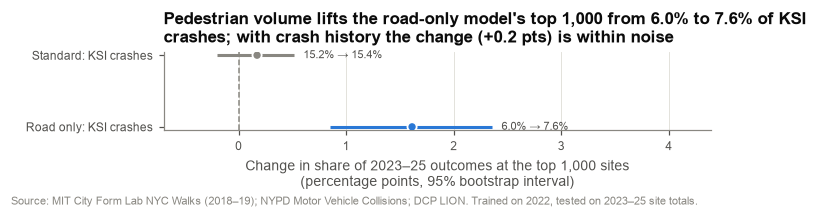

In [6]:
top = holdout[holdout["metric"] == "top1000"].reset_index(drop=True)
labels = [f"{r.spec}: {r.outcome}" for r in top.itertuples()]
fig, ax = plt.subplots(figsize=(FULL_WIDTH, 1.9))
y = np.arange(len(top))
clear = (top["ci_low"] > 0) | (top["ci_high"] < 0)
colors = [MODEL if c else MUTED for c in clear]
ax.hlines(y, 100 * top["ci_low"], 100 * top["ci_high"], color=colors, linewidth=2)
ax.scatter(100 * top["change"], y, color=colors, s=36, zorder=3, edgecolor=SURFACE, linewidth=1.2)
for yi, r in zip(y, top.itertuples()):
    ax.annotate(f"{100 * r.without:.1f}% → {100 * r.with_ped:.1f}%", (100 * r.ci_high, yi),
                xytext=(6, 0), textcoords="offset points", va="center", color=INK_2, fontsize=7.5)
ax.axvline(0, color=MUTED, linestyle="--", linewidth=1)
ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
low, high = 100 * top["ci_low"].min(), 100 * top["ci_high"].max()
ax.set_xlim(min(low, 0) - 0.5, max(high, 0) + 0.6 * (max(high, 0) - min(low, 0)) + 0.5)
ax.set(xlabel="Change in share of 2023–25 outcomes at the top 1,000 sites\n(percentage points, 95% bootstrap interval)")
road = top[(top["spec"] == "Road only") & (top["outcome"] == "KSI crashes")].iloc[0]
std = top[(top["spec"] == "Standard") & (top["outcome"] == "KSI crashes")].iloc[0]
ax.set_title(
    f"Pedestrian volume lifts the road-only model's top 1,000 from {100 * road['without']:.1f}% to "
    f"{100 * road['with_ped']:.1f}% of KSI\ncrashes; with crash history the change ({100 * std['change']:+.1f} pts) is within noise"
)
fig.tight_layout()
source(fig, SOURCE + " Trained on 2022, tested on 2023–25 site totals.")
save(fig, "1_holdout_change")

## 2. Balance: do camera sites differ in foot traffic beyond what road features capture?

In [7]:
# One row per site, with road features from the last panel year. A speed-camera site had a
# speed camera at any time; comparison sites never had a camera of any kind. (Leaving out
# sites near cameras is #27 and isn't applied yet.)
last = panel[panel["year"] == panel["year"].max()].set_index("site_id")
site = last.assign(
    speed_site=panel.groupby("site_id")["speed_active"].max().astype(bool),
    camera_any=panel.groupby("site_id")["camera_site"].max().astype(bool),
)
site = site[site["speed_site"] | ~site["camera_any"]]
treated = site["speed_site"].to_numpy()

# What's left of log pedestrian volume after a linear fit on the road-only features.
X = np.column_stack([np.ones(len(site)), site[ROAD_ONLY].astype(float).to_numpy()])
lp = site["log_ped_volume"].to_numpy()
residual = lp - X @ np.linalg.lstsq(X, lp, rcond=None)[0]


def smd(values, treated):
    """Standardized mean difference, treated minus comparison."""
    a, b = values[treated], values[~treated]
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)


volume = np.expm1(lp)
balance = pd.Series({
    "speed-camera sites": int(treated.sum()),
    "comparison sites": int((~treated).sum()),
    "median pedestrians, camera sites": float(np.median(volume[treated])),
    "median pedestrians, comparison sites": float(np.median(volume[~treated])),
    "SMD, log pedestrian volume": smd(lp, treated),
    "SMD, after road and site features": smd(residual, treated),
})
balance.round(3)

speed-camera sites                        2464.000
comparison sites                        162616.000
median pedestrians, camera sites           523.000
median pedestrians, comparison sites       458.000
SMD, log pedestrian volume                   0.272
SMD, after road and site features           -0.011
dtype: float64

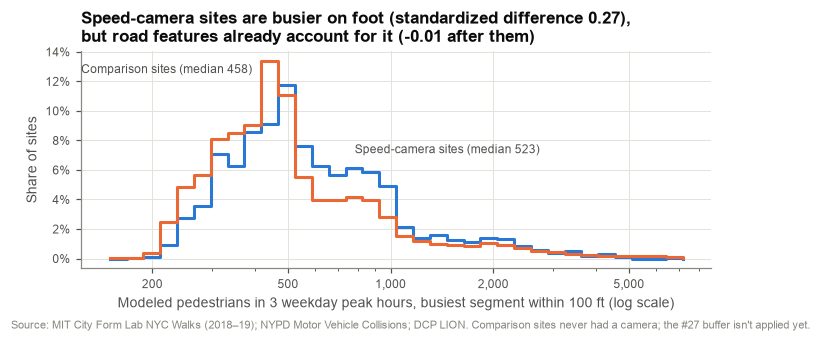

In [8]:
bins = np.geomspace(150, volume.max(), 36)
fig, ax = plt.subplots(figsize=(FULL_WIDTH, 3.0))
for mask, name, color in [(treated, "Speed-camera sites", MODEL), (~treated, "Comparison sites", COMPARISON)]:
    counts, edges = np.histogram(volume[mask], bins=bins)
    share = counts / mask.sum()
    ax.step(edges[:-1], share, where="post", color=color)
    # Comparison sites: label left of their peak; camera sites: above their busy-side shoulder.
    quiet = name == "Comparison sites"
    j = int(np.argmax(share)) if quiet else int(np.searchsorted(edges, 800)) - 1
    ax.annotate(f"{name} (median {np.median(volume[mask]):,.0f})", (edges[j], share[j]),
                xytext=(-6, -2) if quiet else (6, 8), textcoords="offset points", color=INK_2,
                fontsize=8, ha="right" if quiet else "left", va="top" if quiet else "bottom")
ax.set_xscale("log")
ax.set_xticks([200, 500, 1000, 2000, 5000])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set(xlabel="Modeled pedestrians in 3 weekday peak hours, busiest segment within 100 ft (log scale)",
       ylabel="Share of sites")
gap, adjusted = balance["SMD, log pedestrian volume"], balance["SMD, after road and site features"]
ax.set_title(f"Speed-camera sites are {'busier' if gap > 0 else 'quieter'} on foot (standardized difference {gap:.2f}),\n"
             f"but road features already account for it ({adjusted:.2f} after them)")
fig.tight_layout()
source(fig, SOURCE + " Comparison sites never had a camera; the #27 buffer isn't applied yet.")
save(fig, "2_camera_balance")

## 3. Decision

The cell below checks the result against #33's rule. A standardized difference above 0.1 after road features means that, without the feature, the EB baseline would treat camera and comparison sites as alike when they differ in foot traffic. In that case the feature belongs in the baseline even if it doesn't move top-k.

In [9]:
road_ksi = holdout.query("spec == 'Road only' and outcome == 'KSI crashes' and metric == 'top1000'").iloc[0]
improves = road_ksi["ci_low"] > 0
imbalanced = abs(balance["SMD, after road and site features"]) > 0.1
print(f"Road-only top-1,000 KSI capture improves: {improves} ({100 * road_ksi['change']:+.2f} pts, "
      f"95% interval {100 * road_ksi['ci_low']:+.2f} to {100 * road_ksi['ci_high']:+.2f})")
print(f"Camera sites differ in foot traffic beyond road features (|SMD| > 0.1): {imbalanced} "
      f"({balance['SMD, after road and site features']:.2f})")
print("Keep FEATURE_SETS['pedestrian']:", improves or imbalanced)

Road-only top-1,000 KSI capture improves: True (+1.61 pts, 95% interval +0.85 to +2.36)
Camera sites differ in foot traffic beyond road features (|SMD| > 0.1): False (-0.01)
Keep FEATURE_SETS['pedestrian']: True


## 4. Takeaways

- **Keep `FEATURE_SETS["pedestrian"]` in the EB baseline.** Without crash history, adding pedestrian volume raises the share of 2023–25 KSI crashes at the top 1,000 sites from 6.0% to 7.6% (+1.6 points, 95% interval +0.9 to +2.4). That's about a quarter more, and deviance improves too. Doubling a site's peak-hour foot traffic means about 1.5× the expected KSI, holding road features fixed.
- **It adds little to the risk model.** With crash history the top-1,000 change is +0.2 points and the interval includes 0. Deviance improves slightly, and the effect shrinks to about 1.1× per doubling, because past crashes already reflect exposure. It's cheap to keep, but it isn't what drives the ranking.
- **Camera sites are busier on foot, but road features already explain it.** Speed-camera sites have more foot traffic than sites that never had a camera (standardized difference 0.27). After road and site features the gap is about 0, so pedestrian volume doesn't change which comparison sites look like camera sites. It earns its place through prediction, not balance.
- **MapPLUTO (#33 part 2):** test it only as an addition to this road-only + pedestrian baseline. Expect a small gain, since NYC Walks is already built from jobs, retail and homes.
- **Not yet checked:** injury crashes and pedestrian injuries. `NegativeBinomialModel` doesn't converge on those outcomes with these features (overdispersion goes to 0 or infinity), which is a model-layer fix. The comparison group also doesn't have the #27 camera buffer yet.